# Signal vs continuum classification on Belle II features (IDC409 - Introduction to Data Science and AI, Project 1)
**Student:** Daman Kumar (MS23031) - IISER Mohali

**Question.** Can Belle II event-shape features separate **signal** (`type = +1`) from **continuum background** (`type = 0` or `-1`), and how much do classifier choice and feature reduction matter?

> **Label mapping.** The code meanings come from the instructor's clarification relayed by the student: type +1 = signal; type 0 or -1 = continuum; codes 2-5 = other decays. This cannot be verified from the data files. Codes 2-5 are neither category, so I excluded them: an *analysis decision*, not an instructor instruction. The CSV has 35,303 signal, 462 continuum (type 0: 462) and **0 type -1 rows** - none were invented. The sample is 98.7% signal, so accuracy alone is misleading.

Notebook map: 1 data & audit - 2 SQLite - 3 EDA - 4 splits - 5 models - 6 evaluation - 7 reproducing from the saved bundle - 8 feature reduction - 9 pipeline checks and robustness - 10 conclusions.

**How to run this notebook.** From the project folder: `pip install -r requirements.txt`, then `jupyter lab` (or `jupyter nbconvert --to notebook --execute --inplace notebooks/continuum_suppression.ipynb`). Use a kernel of the same Python environment. The first code cell finds the project root automatically (start Jupyter anywhere inside the project, or set `CONTINUUM_ROOT`) and can be re-run safely. The notebook reads the results saved by `python -m src.run_all` (already included); the original CSV must be at `data/raw/data_hep.csv` only if you regenerate them.
*Generated and executed by `python -m src.docs` from saved results (config fingerprint `4d55652eba8e6838`).*

In [1]:
# --- Setup: locate the project root reliably (safe to re-run any number of times) ---------------------------------
# Works whether Jupyter was started in the project root, in notebooks/, or anywhere inside the project tree.
# If the notebook is opened outside the project, set the environment variable CONTINUUM_ROOT to the project folder.
import os, sys, json
from pathlib import Path

def find_project_root():
    env = os.environ.get("CONTINUUM_ROOT")
    starts = ([Path(env).expanduser()] if env else []) + [Path.cwd(), *Path.cwd().parents]
    for base in starts:
        for cand in [base] + sorted(p for p in base.glob("*") if p.is_dir())[:50]:     # the folder itself, or a direct child
            if all((cand / m).exists() for m in ("configs/experiment.json", "src/prepare.py", "src/narrative.py", "templates/report.md.tpl")):   # files unique to this project
                return cand.resolve()
    raise RuntimeError("Project root not found (looked for configs/experiment.json, src/prepare.py and templates/ starting from "
                       f"{Path.cwd()}). Start Jupyter inside the project folder or set CONTINUUM_ROOT=/path/to/continuum_suppression.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))     # no duplicate entries on re-run
os.chdir(PROJECT_ROOT)                                                           # absolute path -> idempotent

import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from src import data, database, predict
from src.paths import ART, FIG, MET, MOD, LOG
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("project root:", PROJECT_ROOT)

project root: /home/claude/continuum_suppression


In [2]:
cfg = data.load_config(); show = lambda n, w=900: display(Image(str(FIG / n), width=w))
tlog = json.load(open(LOG / 'training_log.json'))
# stale-output guard: this notebook must describe results produced under the CURRENT configuration
assert tlog['config_sha256'] == data.config_fingerprint(cfg), 'STALE RESULTS: re-run python -m src.run_all'
print('student:', cfg['student']['name'], cfg['student']['roll'], '| seed', cfg['seed'], '| config fingerprint', data.config_fingerprint(cfg)[:16])
print(json.dumps(cfg['label_mapping'], indent=1)); print(json.dumps(cfg['operating_point'], indent=1))

student: Daman Kumar MS23031 | seed 42 | config fingerprint 4d55652eba8e6838
{
 "status": "INSTRUCTOR-PROVIDED (relayed by the student on 30 Oct 2026); not verifiable from the data files themselves",
 "source": "Clarification from the instructor, relayed by the student: type = +1 is signal; type = 0 or -1 is continuum background; codes 2, 3, 4, 5 represent other decays.",
 "signal_codes": [
  1
 ],
 "continuum_codes": [
  0,
  -1
 ],
 "other_decay_codes": [
  2,
  3,
  4,
  5
 ],
 "excluded_codes": [
  2,
  3,
  4,
  5
 ],
 "exclusion_note": "ANALYSIS DECISION (not an instruction from the instructor): codes 2-5 are neither of the two specified categories, so they are excluded from the primary signal-versus-continuum experiment.",
 "positive_name": "signal",
 "negative_name": "continuum"
}
{
 "rule": "max_continuum_rejection_subject_to_min_signal_efficiency_on_validation",
 "min_signal_efficiency": 0.9,
 "note": "0.90 is an ANALYSIS CHOICE for an illustrative operating point, not an ins

## 1. Data loading, selection and audit
The original CSV is never modified. Provenance: supplied as the course's Belle II sample; how it was generated was not independently verified.

In [3]:
raw = data.load_raw(cfg); audit = json.load(open(MET / 'data_audit.json')); m = cfg['label_mapping']
print('shape', raw.shape, '| SHA-256', audit['csv_sha256']); print('type counts', audit['type_counts'])
selected = raw.loc[raw['type'].isin([1, 0, -1])].copy(); y = (selected['type'] == 1).astype(int)
print('selected', len(selected), '| signal', int(y.sum()), '| continuum', int((1 - y).sum()), '| type -1 rows in file:', int((raw['type'] == -1).sum()), '| signal fraction', round(float(y.mean()), 4))
print('excluded (analysis decision):', audit['experiment']['excluded_by_code'], '| total', audit['experiment']['n_excluded'])
print('majority (predict-all-signal) accuracy:', round(audit['experiment']['majority_accuracy'], 4))
for k in ['missing_total','inf_total','constant_features','duplicate_rows_excl_index','duplicate_feature_vectors','feature_vectors_with_conflicting_type','common_sentinel_hits']: print(f'{k:42s}', audit[k])
print('\nunnamed index-like column:'); print(json.dumps(audit['index_column'], indent=1))

shape (70606, 61) | SHA-256 fadaeb5a20a7809658f760eb4b49feef3ee89c7823d1a215356d40e20266cf67
type counts {'0': 462, '1': 35303, '2': 23333, '3': 8172, '4': 1879, '5': 1457}
selected 35765 | signal 35303 | continuum 462 | type -1 rows in file: 0 | signal fraction 0.9871
excluded (analysis decision): {'2': 23333, '3': 8172, '4': 1879, '5': 1457} | total 34841
majority (predict-all-signal) accuracy: 0.9871
missing_total                              0
inf_total                                  0
constant_features                          []
duplicate_rows_excl_index                  0
duplicate_feature_vectors                  0
feature_vectors_with_conflicting_type      0
common_sentinel_hits                       {'-999': 0, '-999.0': 0, '-9999': 0, '9999': 0, '999': 0, '-1': 0}

unnamed index-like column:
{
 "unique": false,
 "n_repeated_values": 1766,
 "equals_row_number": false,
 "range_by_type": {
  "0": [
   239,
   50699
  ],
  "1": [
   0,
   35302
  ],
  "2": [
   27,
   2483999


**Findings.** 70,606 rows, 59 numeric features. No missing/infinite values, constant columns, duplicate feature vectors or conflicting duplicates. The unnamed first column repeats 1,766 values, is unique only within each type code and its range depends on the code; that pattern resembles a running index from separate files, but its origin is undocumented, so I do not assert it. It is not a reliable event identifier and could encode the label, so it is **excluded from all predictors** (with `type` and every identifier). Exact zeros occur only in CLEO-cone variables and are kept.

## 2. SQLite database: write, read, modify, verify

In [4]:
con = database.connect(cfg)
print(pd.read_sql("SELECT name, type FROM sqlite_master WHERE type IN ('table','view')", con))
print(pd.read_sql("SELECT * FROM type_mapping", con))
print(pd.read_sql("SELECT split, role, COUNT(*) n FROM events GROUP BY split, role ORDER BY split, role", con))
print('primary_events view rows:', con.execute("SELECT COUNT(*) FROM primary_events").fetchone()[0], '| distinct codes:', [r[0] for r in con.execute("SELECT DISTINCT type FROM primary_events ORDER BY type")])
chk = database.verify(con, raw, cfg); print({k: v for k, v in chk.items() if isinstance(v, bool)})
con.execute("CREATE TEMP TABLE scratch AS SELECT row_id, type, target FROM events WHERE in_primary = 1")     # MODIFY a scratch copy, project DB untouched
con.execute("UPDATE scratch SET target = 1 - target WHERE type = 0")
print('scratch UPDATE changed', con.execute("SELECT COUNT(*) FROM scratch s JOIN events e USING(row_id) WHERE s.target <> e.target").fetchone()[0], 'rows (= number of type-0 rows:', int((raw.type==0).sum()), ')')
con.close()

             name   type
0      events_raw  table
1          events  table
2    type_mapping  table
3            meta  table
4  primary_events   view
   code         role  in_primary_experiment  n_rows                                             source
0    -1    continuum                      1       0                    instructor-provided via student
1     0    continuum                      1     462                    instructor-provided via student
2     1       signal                      1   35303                    instructor-provided via student
3     2  other_decay                      0   23333  instructor-provided via student; excluded by a...
4     3  other_decay                      0    8172  instructor-provided via student; excluded by a...
5     4  other_decay                      0    1879  instructor-provided via student; excluded by a...
6     5  other_decay                      0    1457  instructor-provided via student; excluded by a...
      split         role  

{'raw_table_rowcount_matches_csv': True, 'raw_table_values_identical_to_csv': True, 'raw_type_and_index_identical': True, 'events_features_equal_raw': True, 'primary_view_rows_equal_pandas_subset': True, 'primary_view_only_intended_codes': True, 'target_matches_pandas_mapping_on_primary': True, 'target_null_for_excluded_rows': True, 'primary_rows_have_target_and_split': True, 'excluded_rows_marked_excluded': True, 'type_mapping_counts_match_csv': True, 'no_type_minus1_rows_created': True, 'all_ok': True}
scratch UPDATE changed 462 rows (= number of type-0 rows: 462 )


`events_raw` keeps every original value (verified identical to the CSV). `type_mapping`, `events.role`, `in_primary`, `target`, `split` and `n_rows` were **modified with SQL `UPDATE`**, read back and checked against pandas; the `primary_events` view is exactly the modelling subset.

## 3. Exploratory data analysis (training rows for decisions)

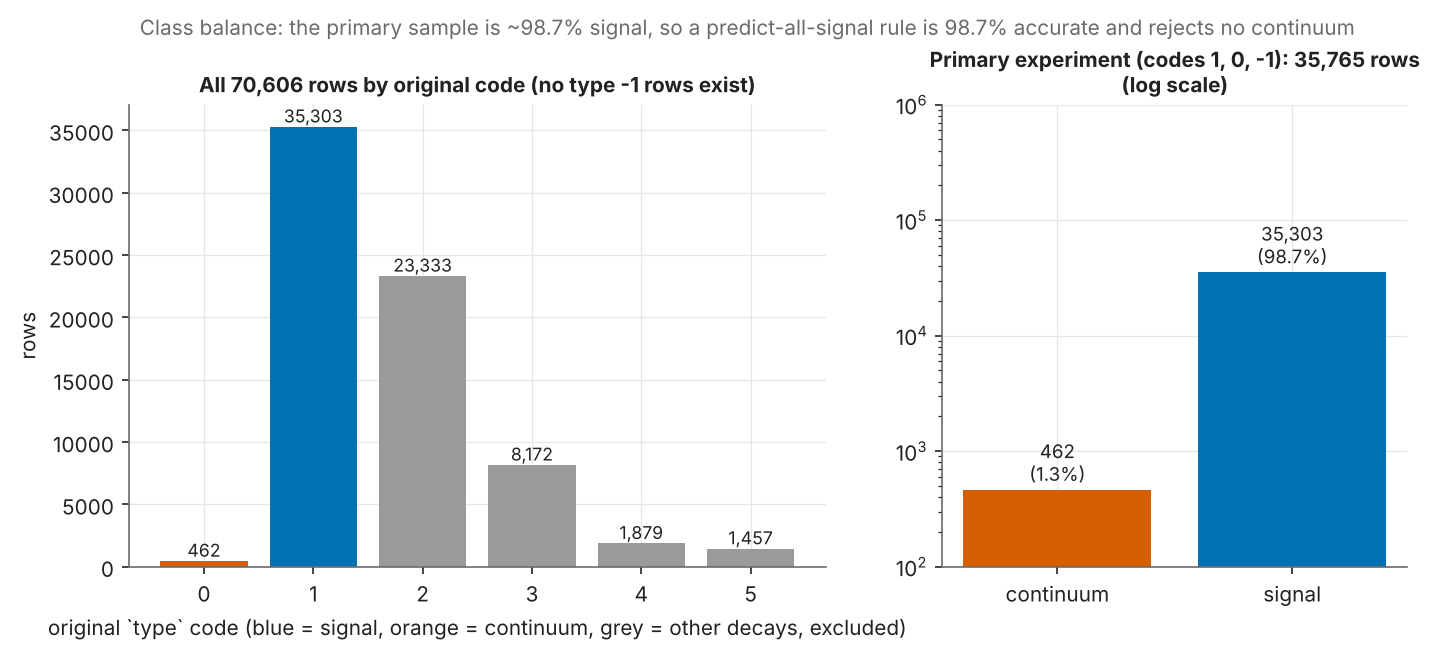

In [5]:
show('01_label_balance.png', 950)

**Shows:** all six original codes and the primary experiment (35,303 signal vs 462 continuum, log scale). **Cannot conclude:** the class sizes say nothing about physics; they show why accuracy is not informative (predict-all-signal scores 0.987).

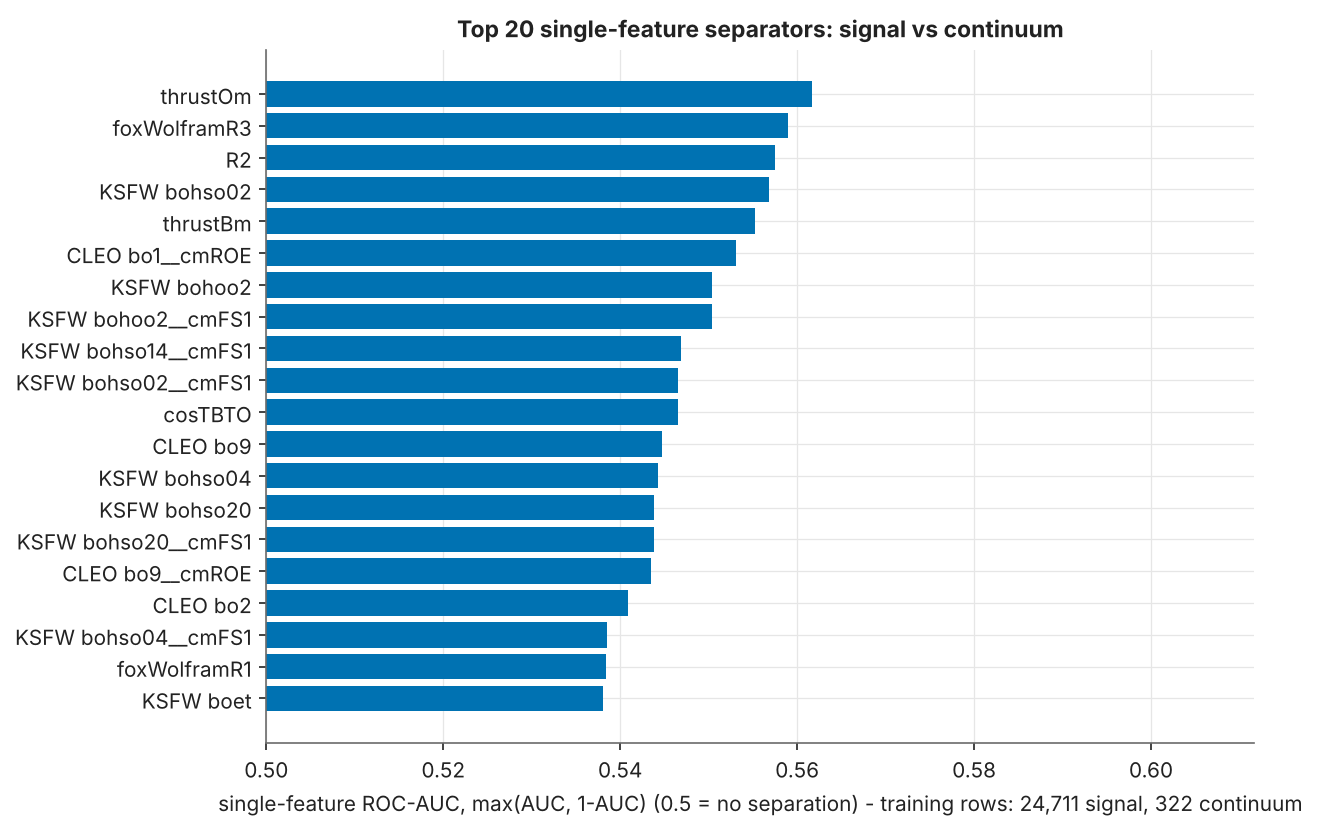

In [6]:
show('02_univariate_separation.png', 700)

**Shows:** single-feature separation on training rows: the best feature (`thrustOm`) reaches an AUC of only 0.562. **Cannot conclude:** AUC ignores correlation between features and says nothing about causal importance.

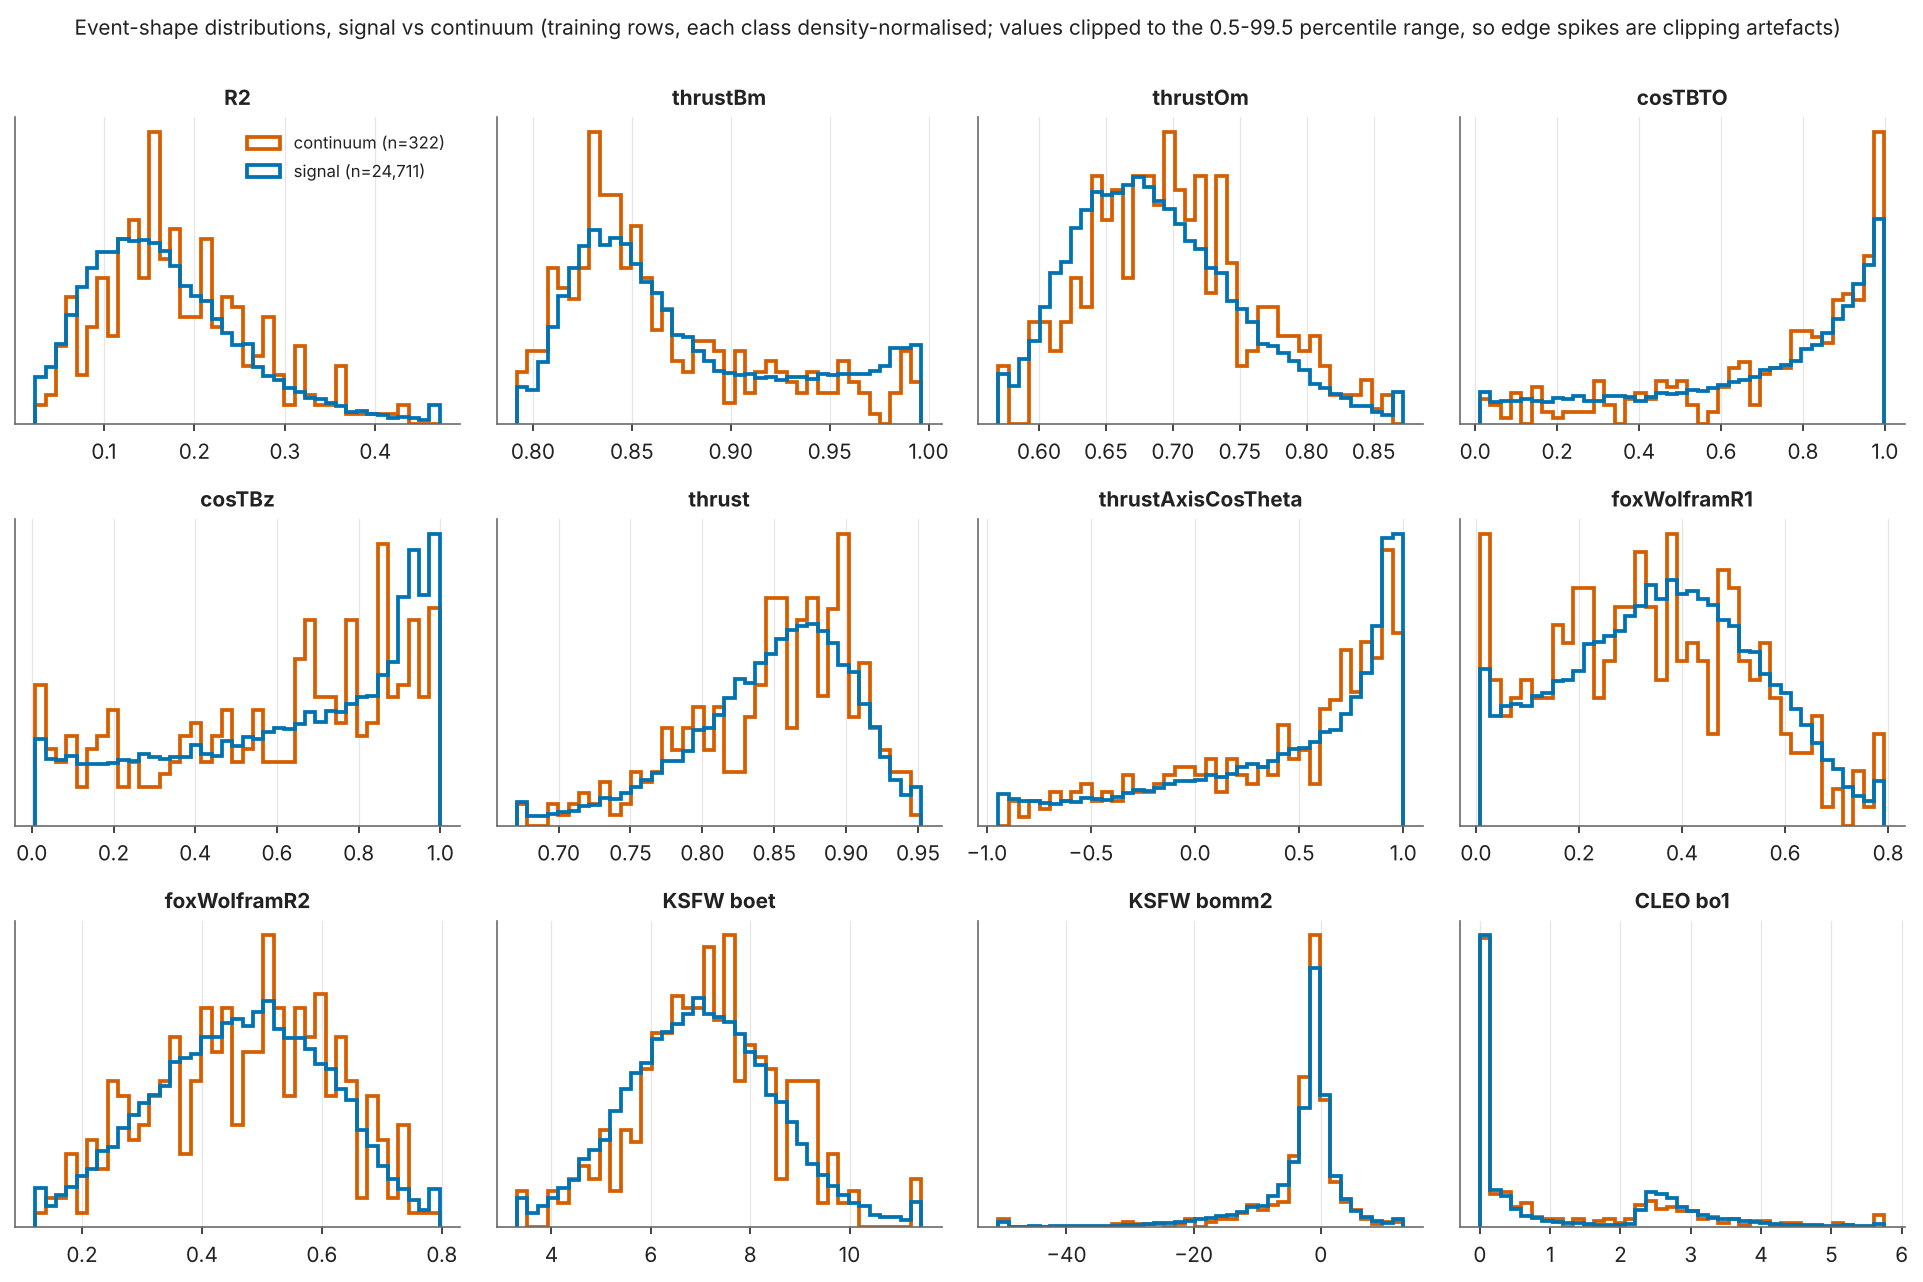

In [7]:
show('03_event_shape_distributions.png', 1100)

**Shows:** the signal and continuum distributions overlap almost completely. **Note:** continuum is normally expected to be more jet-like (higher R2/thrust, cosTBTO near 1) than B-pair signal; the type-0 events show the signal-like pattern. This is flagged for the instructor, not 'fixed' by changing the mapping.

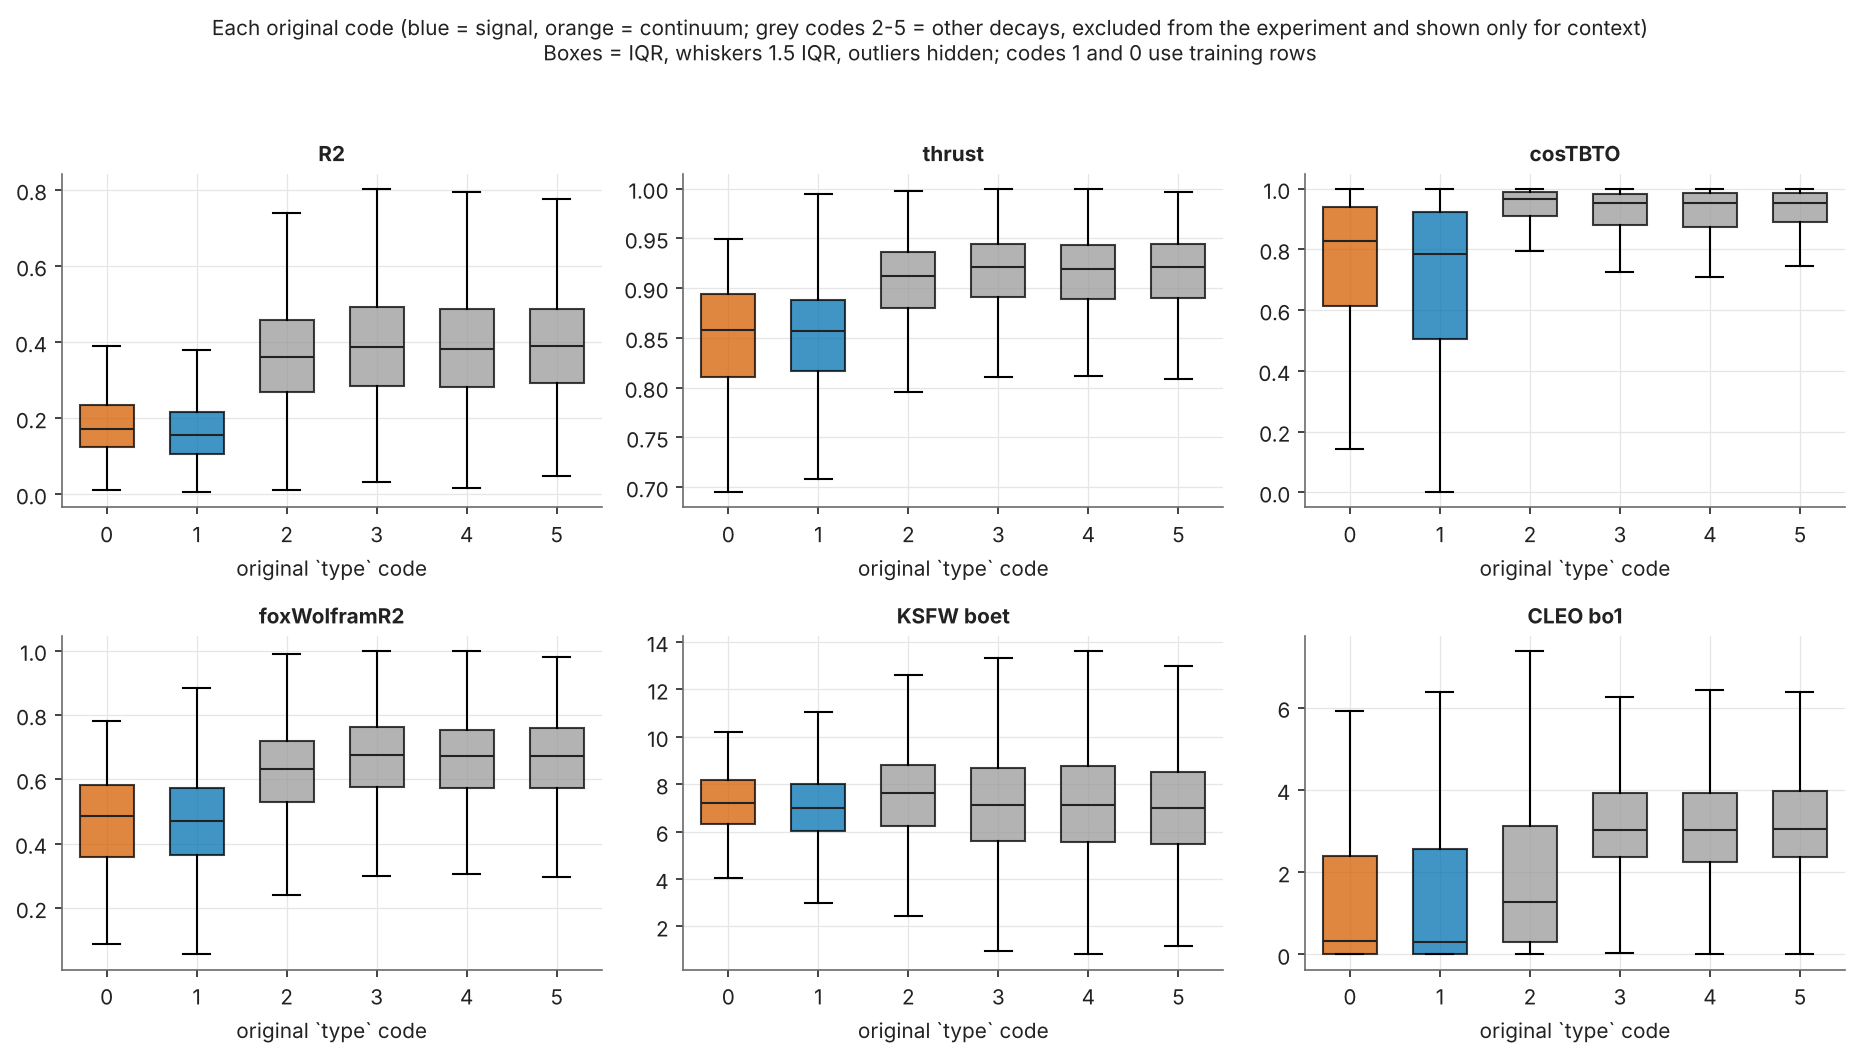

In [8]:
show('04_distributions_by_type_code.png', 1000)

**Shows:** each original code (grey = other decays 2-5, excluded; shown for context only).

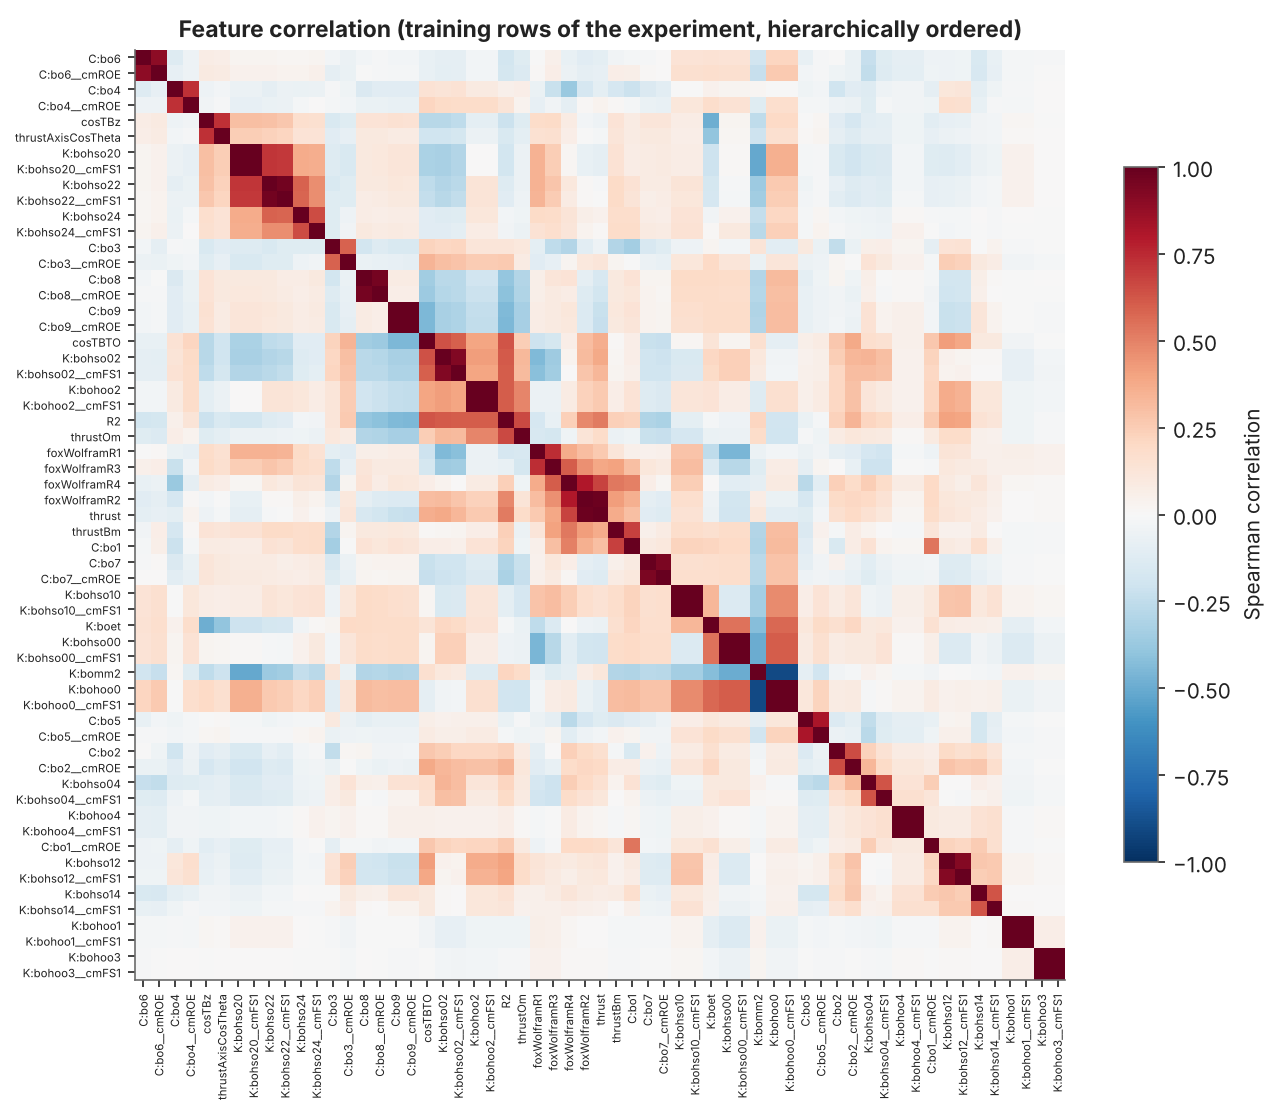

                            a                                  b  spearman
0   KSFWVariables__bohoo3__bc   KSFWVariables__bohoo3__cmFS1__bc  1.000000
1   KSFWVariables__bohoo1__bc   KSFWVariables__bohoo1__cmFS1__bc  1.000000
2   KSFWVariables__bohoo0__bc   KSFWVariables__bohoo0__cmFS1__bc  1.000000
3   KSFWVariables__bohoo4__bc   KSFWVariables__bohoo4__cmFS1__bc  1.000000
4  KSFWVariables__bohso10__bc  KSFWVariables__bohso10__cmFS1__bc  1.000000
5  KSFWVariables__bohso20__bc  KSFWVariables__bohso20__cmFS1__bc  1.000000
6  KSFWVariables__bohso00__bc  KSFWVariables__bohso00__cmFS1__bc  1.000000
7   KSFWVariables__bohoo2__bc   KSFWVariables__bohoo2__cmFS1__bc  1.000000
8         CleoConeCS__bo9__bc         CleoConeCS__bo9__cmROE__bc  0.996862
9                foxWolframR2                             thrust  0.977027


In [9]:
show('05_correlation_heatmap.png', 800); print(pd.read_csv(MET/'highly_correlated_pairs_train.csv').head(10))

**Shows:** strong redundancy: KSFW moments from B primary daughters and from final-state particles correlate up to 1.0; 17 feature pairs have |r| >= 0.9. This motivates the correlation filter. Correlation does not mean the variables are physically identical.

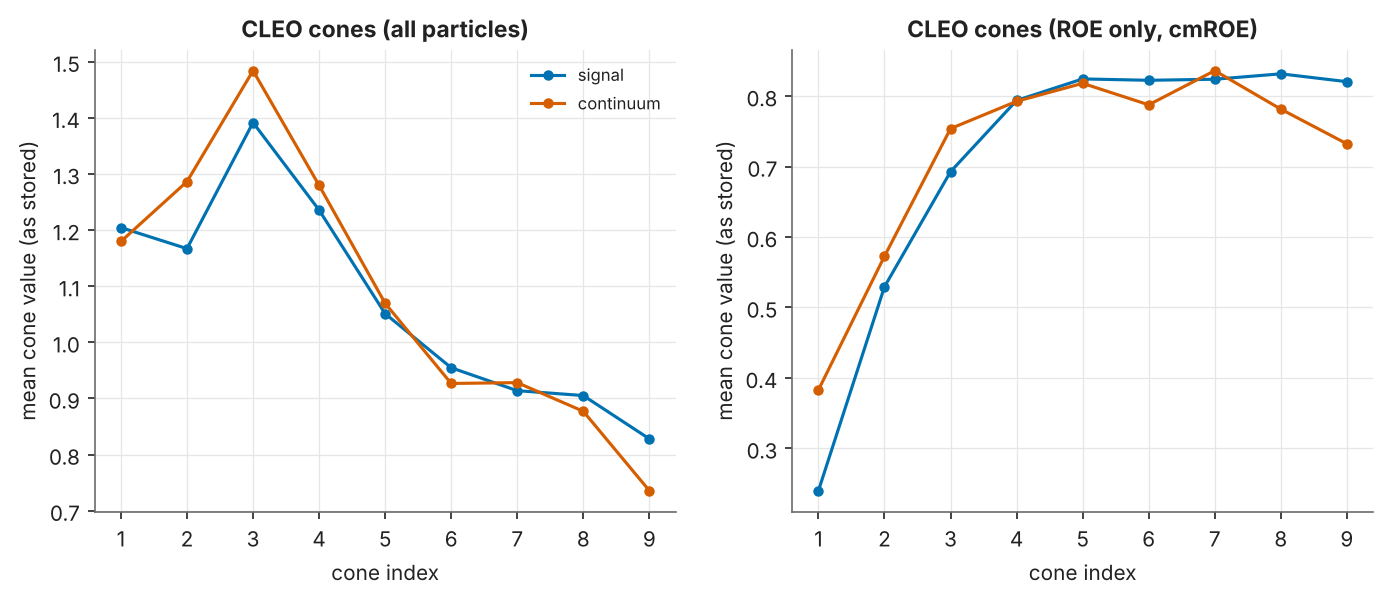

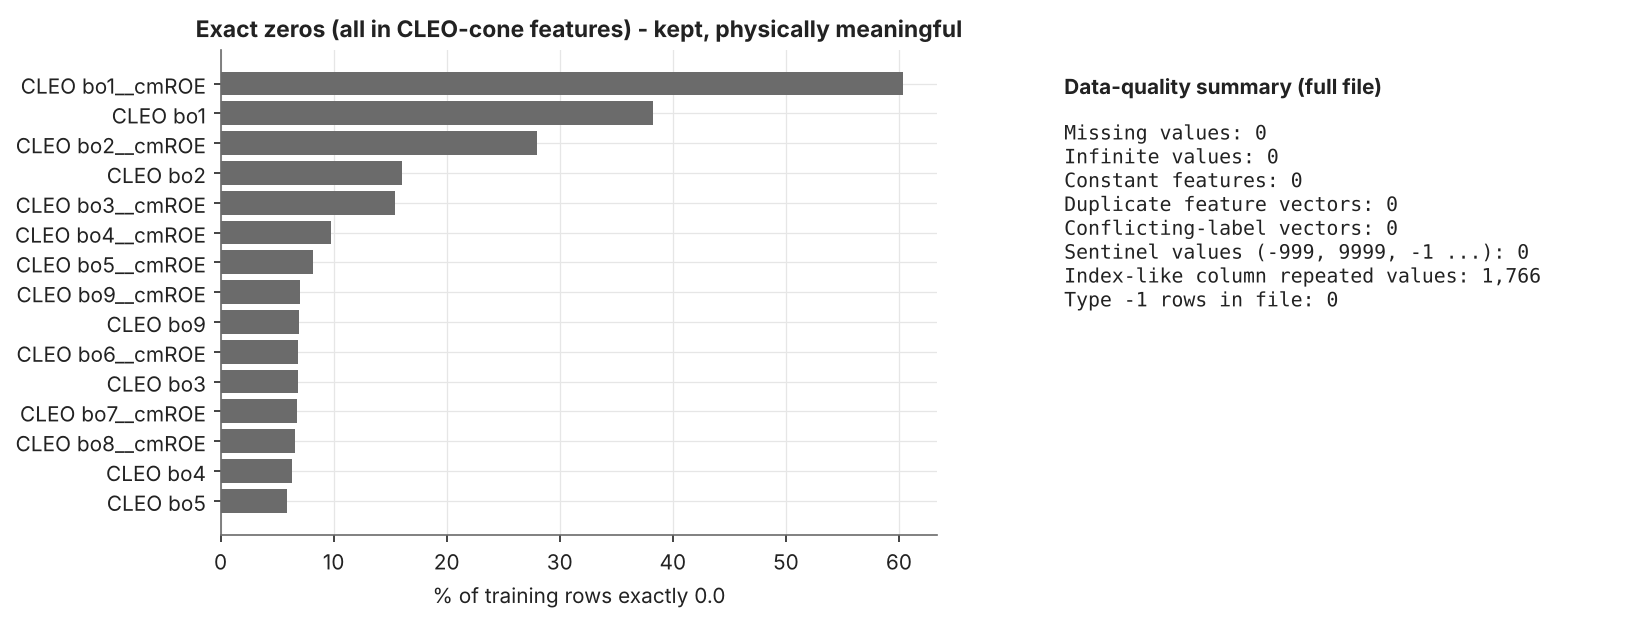

In [10]:
show('06_cleo_cone_profiles.png', 900); show('07_data_quality.png', 1000)

## 4. Train / validation / test split

In [11]:
sp = pd.read_csv(MET/'split_assignments.csv')
print(pd.crosstab([sp.in_primary, sp.role], sp.split, margins=True)); g = sp[sp.in_primary == 1]
print(pd.crosstab(g.split, g.role, margins=True)); print('class proportion by split:', g.groupby('split').target.mean().round(4).to_dict())
print('primary rows:', len(g), '| groups spanning >1 split:', int((g.groupby('group').split.nunique() > 1).sum()), '| excluded rows in train/val/test:', int(((sp.in_primary == 0) & sp.split.isin(['train','val','test'])).sum()))

split                   excluded  test  train   val    All
in_primary role                                           
0          other_decay     34841     0      0     0  34841
1          continuum           0    69    322    71    462
           signal              0  5297  24711  5295  35303
All                        34841  5366  25033  5366  70606
role   continuum  signal    All
split                          
test          69    5297   5366
train        322   24711  25033
val           71    5295   5366
All          462   35303  35765
class proportion by split: {'test': 0.9871, 'train': 0.9871, 'val': 0.9868}
primary rows: 35765 | groups spanning >1 split: 0 | excluded rows in train/val/test: 0


Stratified 70/15/15 (seed 42) on the signal/continuum class, so every split keeps the class proportions: train 24,711 / 322, validation 5,295 / 71, test 5,297 / 69 (signal / continuum). No physical event identifier exists; rows are grouped by a rounded feature-vector hash so duplicates could never cross splits (none exist). **Limitation:** distinct rows from one physical event cannot be detected. Scalers and class weights are fitted on training rows only; validation and test data are never resampled or weighted; the test split is scored once.

## 5. Models and tuning

In [12]:
rows=[]
for k, v in tlog['models'].items():
    if k.endswith('|full'): rows.append({'model': k.split('|')[0], 'features used': v['n_features_used'], 'val AUC': round(v['best_val_auc'],4), 'best params': v['best_params'], 'configs tried': len(v['search']), 'tuning s': v['tuning_seconds']})
display(pd.DataFrame(rows)); print('Best by VALIDATION AUC:', tlog['best_by_validation_auc']); print('single-feature cut uses:', tlog['models']['single_cut|full']['single_cut_feature'], '(best of', tlog['models']['single_cut|full']['n_features'], 'candidates)')
display(pd.read_csv(MET/'class_weighting_comparison_validation.csv'))

,model,features used,val AUC,best params,configs tried,tuning s
0,majority,0,0.5000,{},1,0.00
1,single_cut,1,0.4650,{},1,1.06
2,logreg,59,0.5052,"{'C': 10.0, 'class_weight': None}",8,1.59
3,tree,59,0.5429,"{'class_weight': 'balanced', 'max_depth': 8, '...",12,12.83
4,forest,59,0.5619,"{'min_samples_leaf': 1, 'max_features': 'sqrt'...",6,99.44
5,boosting,59,0.5484,"{'max_leaf_nodes': 31, 'learning_rate': 0.2, '...",8,69.58


Best by VALIDATION AUC: forest|full
single-feature cut uses: thrustOm (best of 59 candidates)


,Model,"best validation AUC, no weighting","best validation AUC, training-only class weighting",weighting chosen
0,Logistic regression,0.505,0.505,no
1,Decision tree,0.518,0.543,yes
2,Random forest,0.508,0.562,yes
3,Gradient boosting (HistGB),0.539,0.548,yes


**Four learned classifiers** (logistic regression, decision tree, random forest, gradient boosting) and **two baselines** (majority class; single-feature cut using one feature). Training-only class weighting is part of each learned model's search and is compared on validation ROC-AUC (second table). Selection metric: validation ROC-AUC (threshold-free, never test).

## 6. Evaluation on the held-out test set

In [13]:
R = pd.read_csv(MET/'results_full.csv'); n_sig, n_con = int(R.n_signal_test.iloc[0]), int(R.n_continuum_test.iloc[0]); print('test denominators: signal', n_sig, '| continuum', n_con)
display(Markdown('**Table A - required metrics at the validation-selected operating point**')); display(pd.read_csv(MET/'table_A_required_metrics_operating_point.csv'))
display(Markdown('**Table B - signal efficiency and continuum rejection (exact 95% CI)**')); display(pd.read_csv(MET/'table_B_efficiency_rejection_operating_point.csv'))
display(Markdown('**Table C - fixed threshold 0.5 (ROC-AUC identical: same scores, same rows)**')); display(pd.read_csv(MET/'table_C_threshold_0.5.csv'))
display(Markdown('**Table D - per-class precision / recall / F1**')); display(pd.read_csv(MET/'table_D_per_class_operating_point.csv'))

test denominators: signal 5297 | continuum 69


**Table A - required metrics at the validation-selected operating point**

,Model,Accuracy,Precision (signal),Recall (signal),F1 (signal),ROC-AUC [95% CI],Features used,Threshold,Final fit (s)
0,Majority class,0.987,0.987,1.000,0.994,"0.500 [0.500, 0.500]",0,1.000,0.0
1,Single-feature cut,0.899,0.988,0.909,0.947,"0.567 [0.504, 0.630]",1 (thrustOm; 59 examined),0.001,0.5
2,Logistic regression,0.894,0.987,0.904,0.944,"0.530 [0.460, 0.598]",59,0.979,0.1
3,Decision tree,0.923,0.987,0.934,0.960,"0.522 [0.459, 0.588]",59,0.254,1.2
4,Random forest,0.922,0.987,0.933,0.959,"0.505 [0.434, 0.573]",59,0.970,14.1
5,Gradient boosting (HistGB),0.897,0.988,0.907,0.946,"0.545 [0.475, 0.617]",59,0.994,11.7


**Table B - signal efficiency and continuum rejection (exact 95% CI)**

,Model,"Signal efficiency [95% exact CI], n=5,297","Continuum rejection [95% exact CI], n=69",Continuum acceptance,Balanced accuracy,Macro-F1
0,Majority class,"100.0% [99.9%, 100.0%]","0.0% [0.0%, 5.2%]",100.0%,0.500,0.497
1,Single-feature cut,"90.9% [90.1%, 91.6%]","13.0% [6.1%, 23.3%]",87.0%,0.520,0.489
2,Logistic regression,"90.4% [89.5%, 91.2%]","11.6% [5.1%, 21.6%]",88.4%,0.510,0.485
3,Decision tree,"93.4% [92.7%, 94.1%]","5.8% [1.6%, 14.2%]",94.2%,0.496,0.489
4,Random forest,"93.3% [92.6%, 94.0%]","5.8% [1.6%, 14.2%]",94.2%,0.495,0.489
5,Gradient boosting (HistGB),"90.7% [89.9%, 91.5%]","13.0% [6.1%, 23.3%]",87.0%,0.519,0.489


**Table C - fixed threshold 0.5 (ROC-AUC identical: same scores, same rows)**

,Model,Accuracy,Precision (signal),Recall (signal),F1 (signal),ROC-AUC,Signal efficiency,Continuum rejection (n=69),Balanced accuracy,Macro-F1
0,Majority class,0.987,0.987,1.000,0.994,0.500,100.0%,0.0%,0.500,0.497
1,Single-feature cut,0.428,0.991,0.425,0.595,0.567,42.5%,71.0%,0.567,0.313
2,Logistic regression,0.986,0.987,0.999,0.993,0.530,99.9%,0.0%,0.500,0.497
3,Decision tree,0.605,0.988,0.607,0.752,0.522,60.7%,44.9%,0.528,0.390
4,Random forest,0.987,0.987,1.000,0.994,0.505,100.0%,0.0%,0.500,0.497
5,Gradient boosting (HistGB),0.987,0.987,1.000,0.993,0.545,100.0%,0.0%,0.500,0.497


**Table D - per-class precision / recall / F1**

,Model,Signal P,Signal R,Signal F1,Continuum P,Continuum R,Continuum F1
0,Majority class,0.987,1.000,0.994,0.000,0.000,0.000
1,Single-feature cut,0.988,0.909,0.947,0.018,0.130,0.032
2,Logistic regression,0.987,0.904,0.944,0.015,0.116,0.027
3,Decision tree,0.987,0.934,0.960,0.011,0.058,0.019
4,Random forest,0.987,0.933,0.959,0.011,0.058,0.019
5,Gradient boosting (HistGB),0.988,0.907,0.946,0.018,0.130,0.032


The majority baseline predicts every row signal: accuracy 0.987 but balanced accuracy 0.500 and 0% continuum rejection. The operating point maximises *validation* continuum rejection subject to signal efficiency >= 90% (an analysis choice); it was frozen before the test set was scored and the test values are what they are. Exact (Clopper-Pearson) intervals use the real denominators; AUC intervals use a stratified bootstrap.

,comparison,model,auc_diff,ci_lo,ci_hi,ci_excludes_zero
0,forest|full minus majority|full,majority,0.0049,-0.0659,0.0732,False
1,forest|full minus single_cut|full,single_cut,-0.0620,-0.1521,0.0340,False
2,forest|full minus logreg|full,logreg,-0.0247,-0.1018,0.0555,False
3,forest|full minus tree|full,tree,-0.0170,-0.1004,0.0637,False
4,forest|full minus boosting|full,boosting,-0.0400,-0.1120,0.0307,False


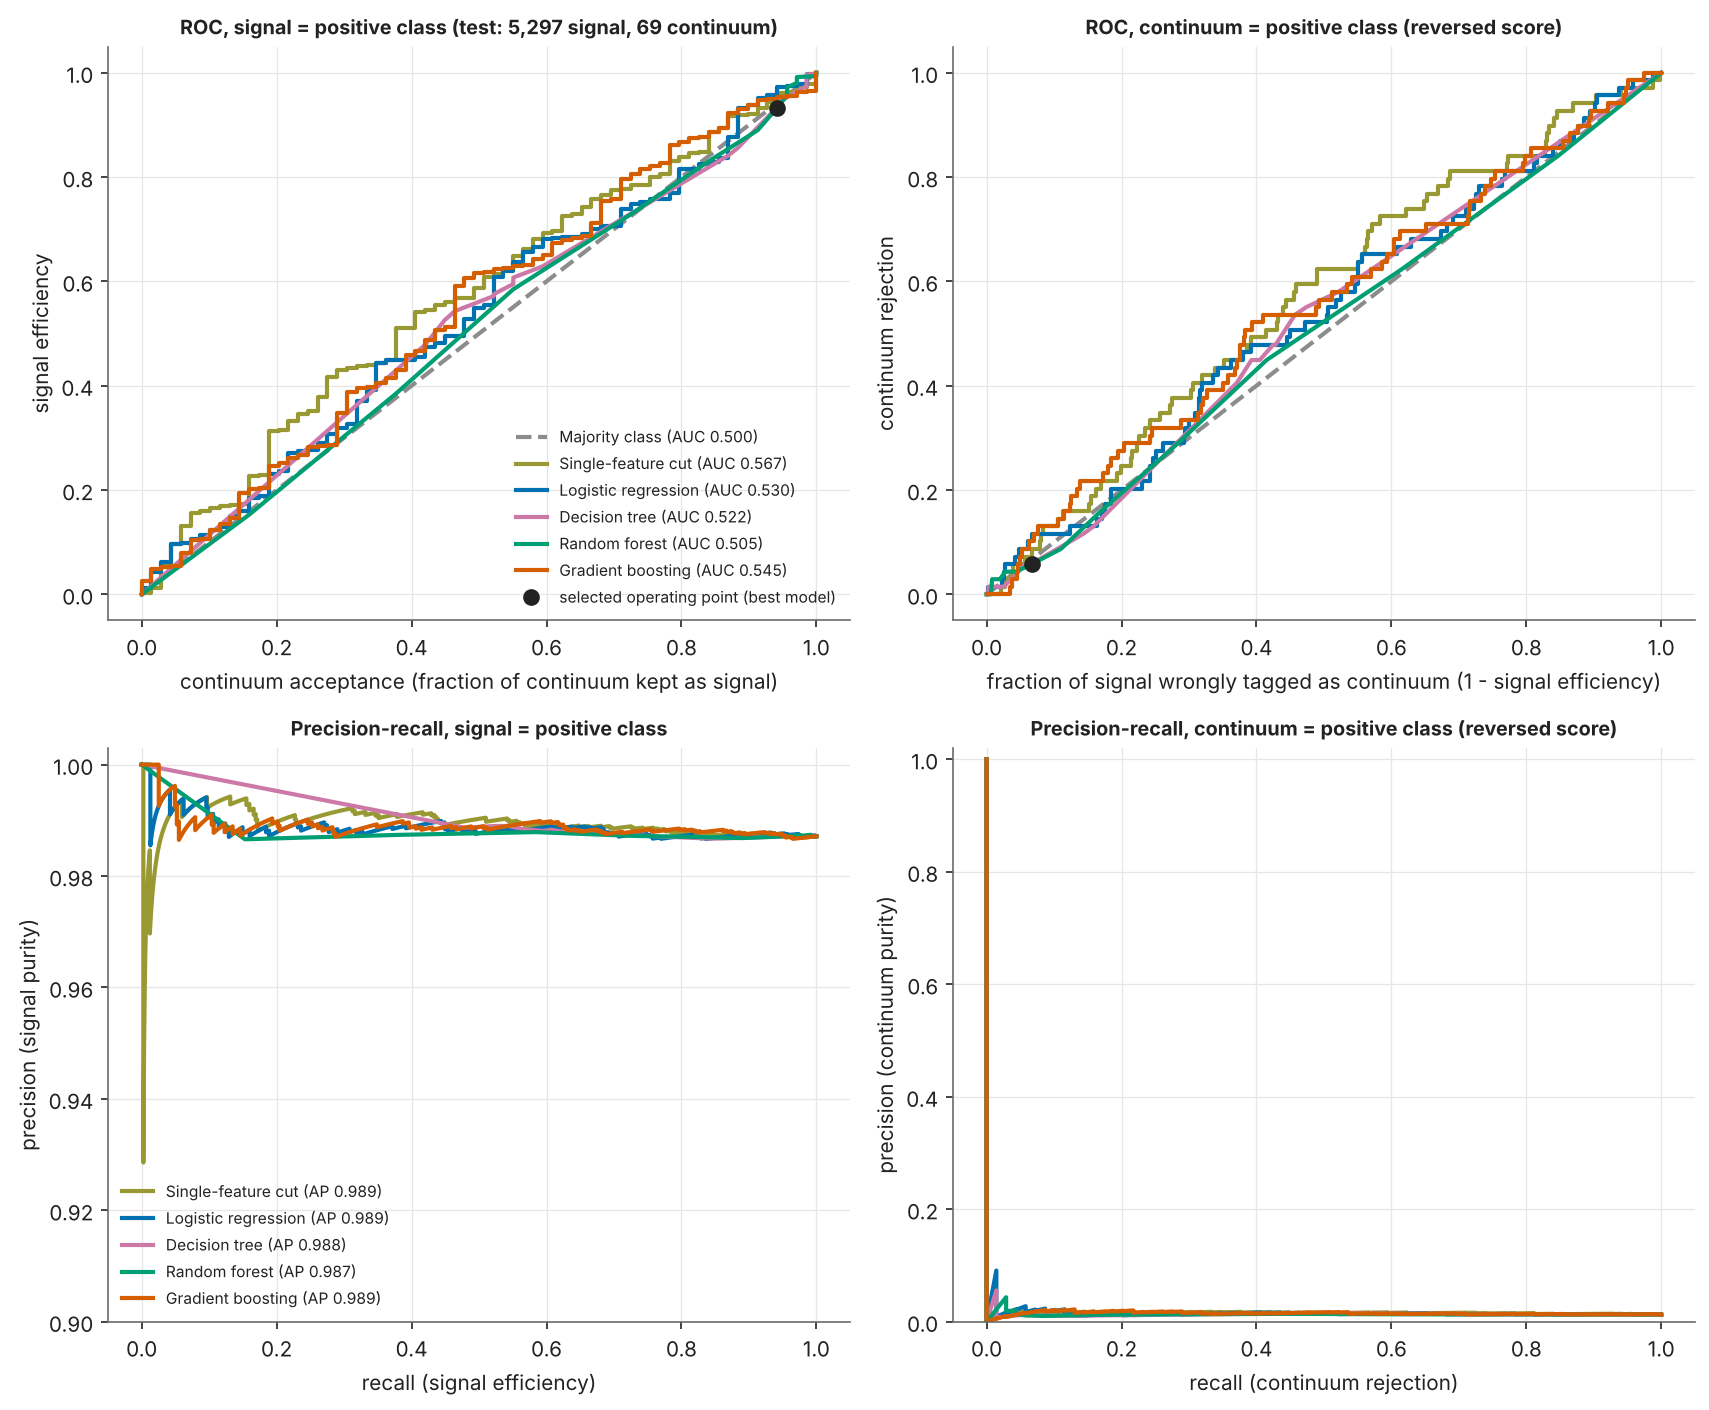

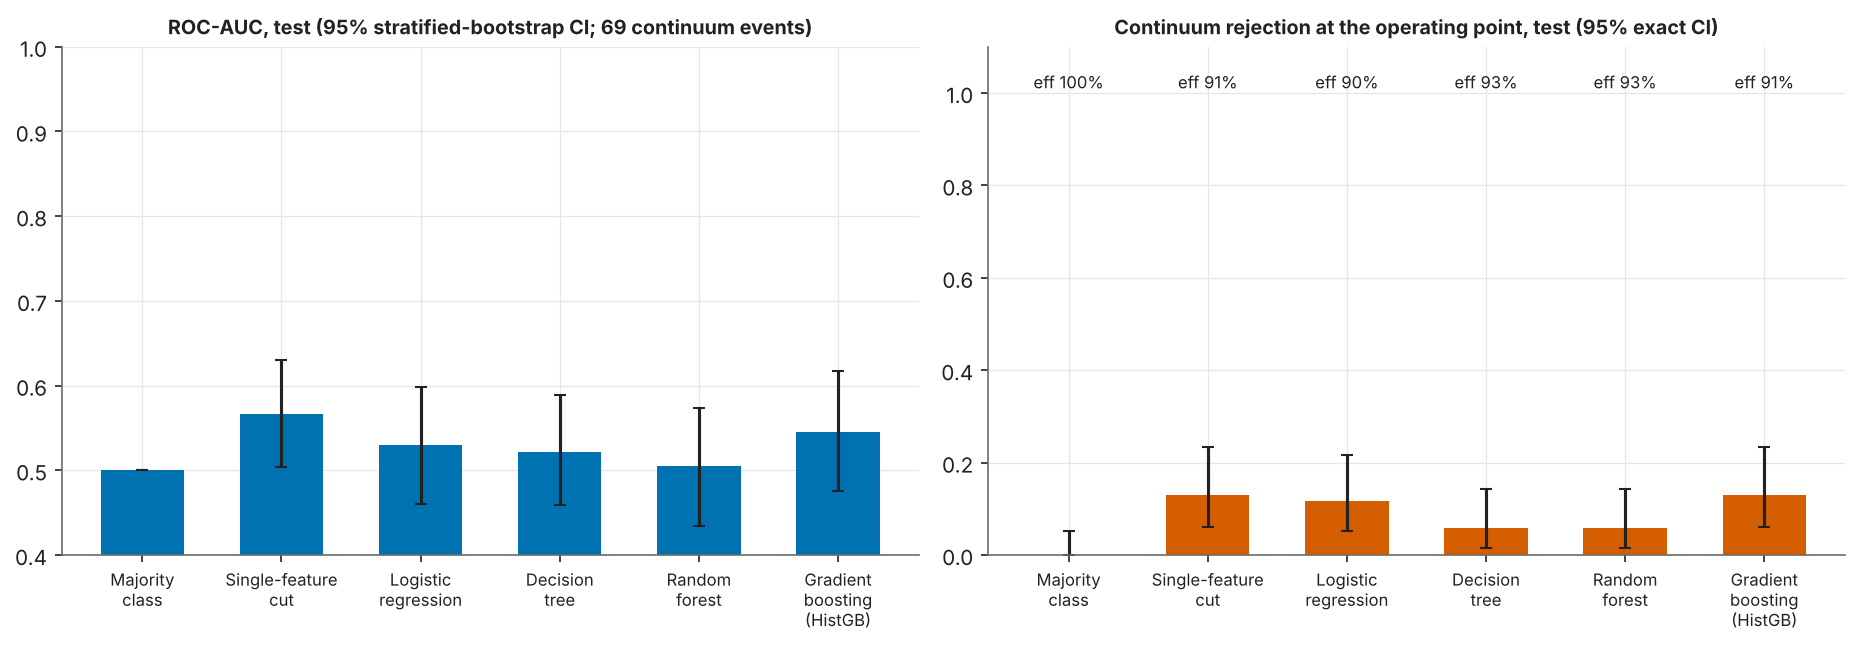

In [14]:
display(pd.read_csv(MET/'paired_auc_vs_best.csv').round(4)); show('10_roc_pr.png', 1000); show('14_model_comparison.png', 1000)

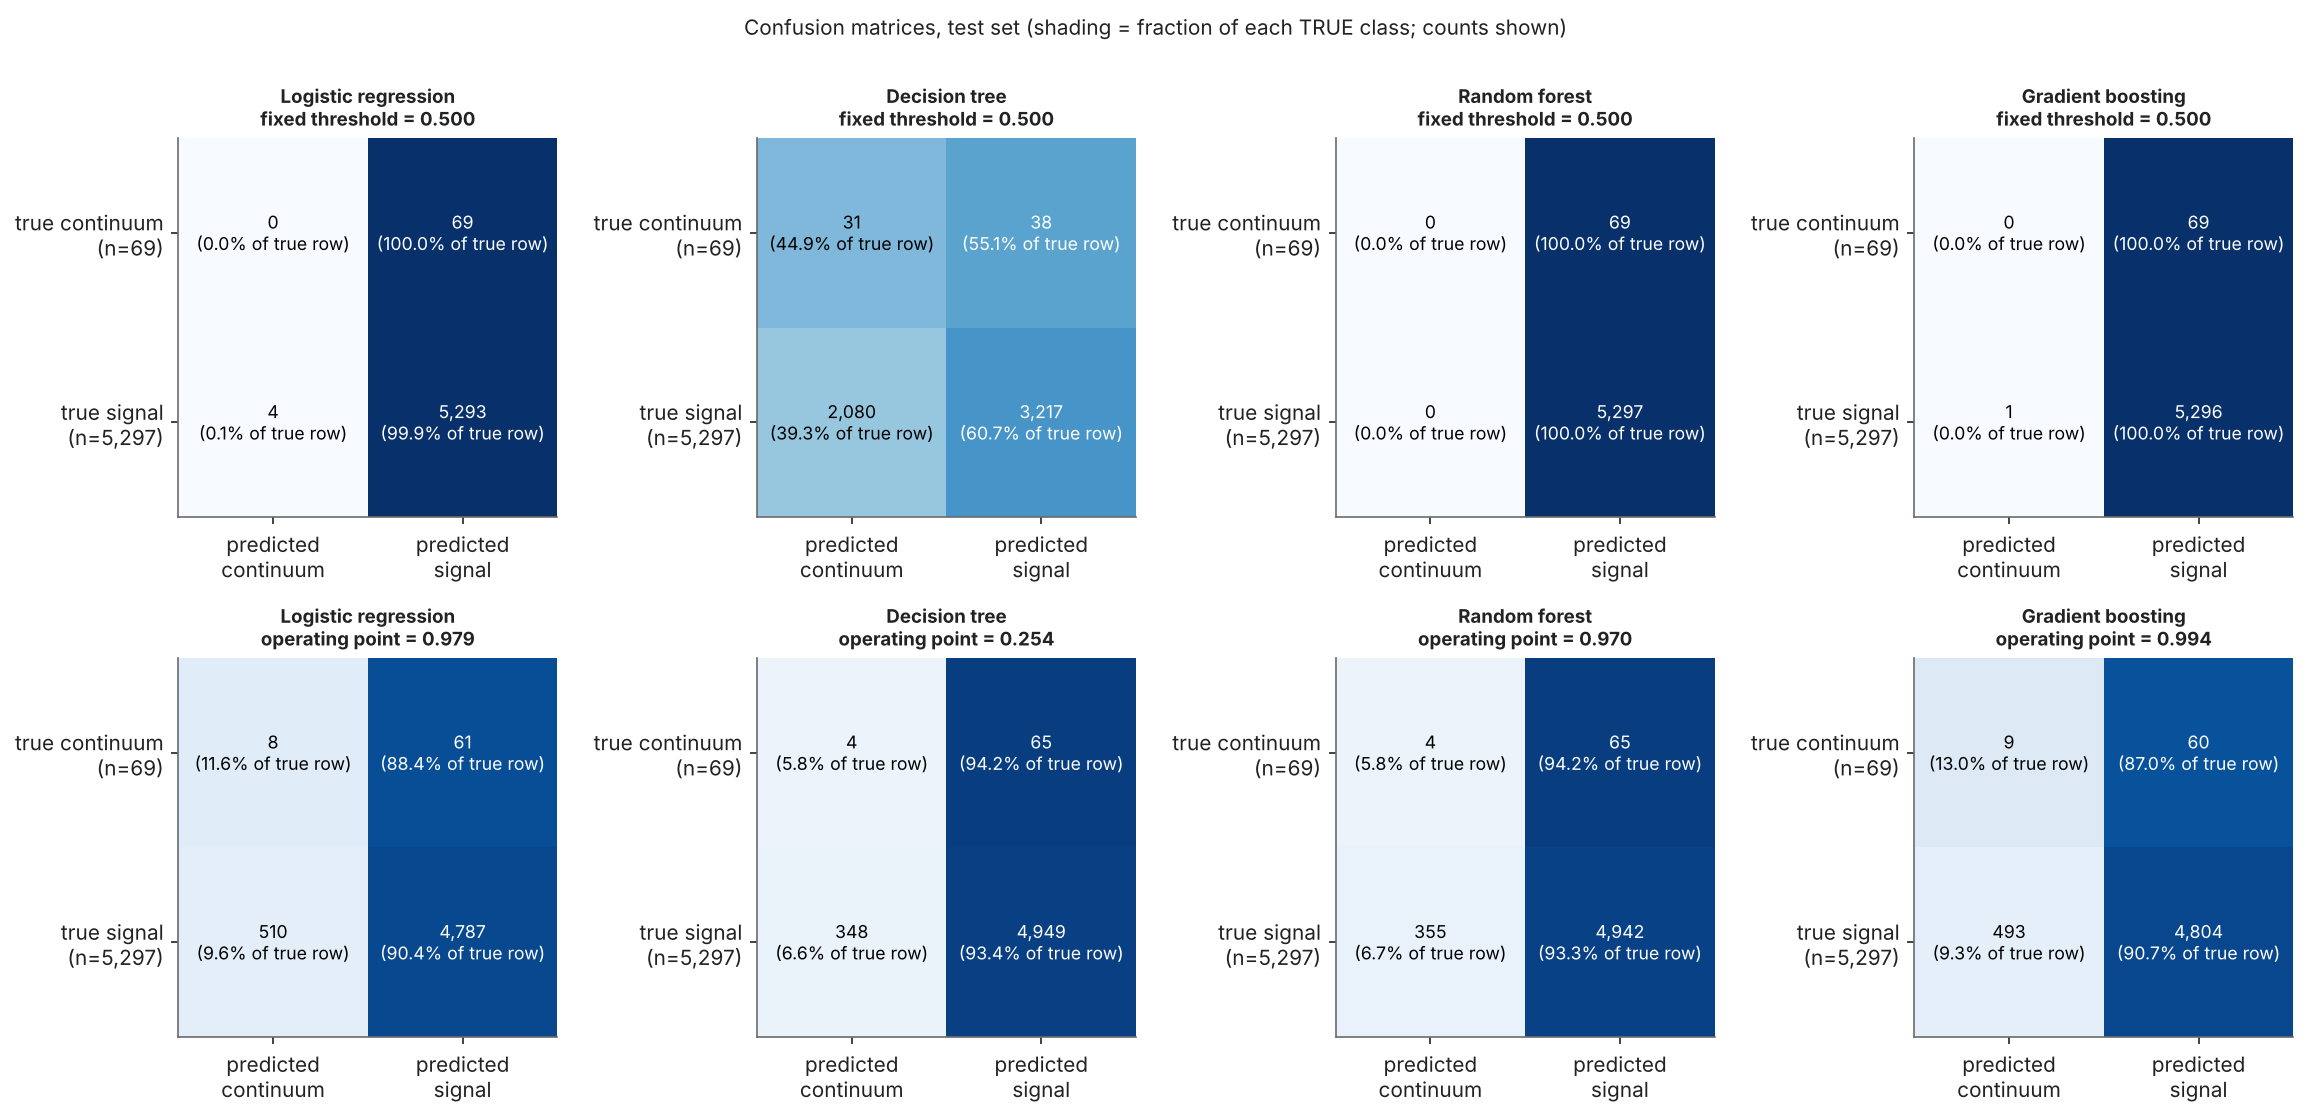

In [15]:
show('11_confusion_matrices.png', 1150)

Counts and row-normalised shading are shown for the fixed threshold 0.5 (top) and the validation-selected operating point (bottom). Rows are the TRUE classes, so each row sums to the true class size.

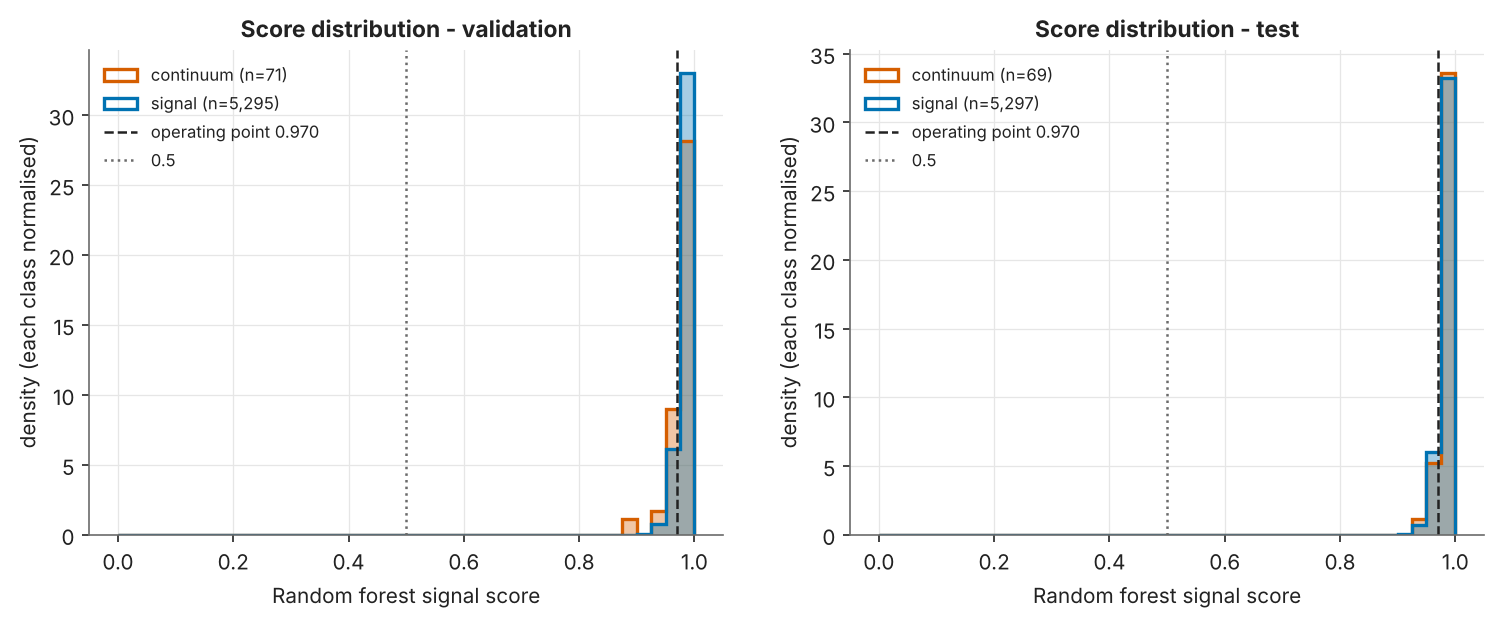

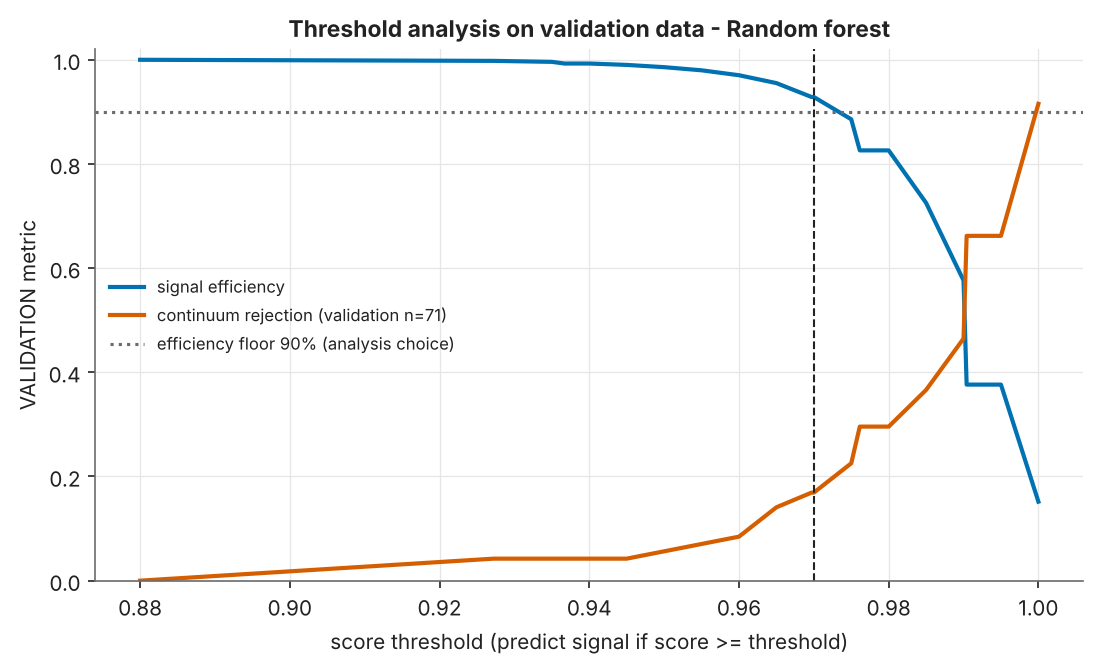

In [16]:
show('12_score_distribution.png', 1000); show('13_threshold_analysis.png', 700)

**Selected model: `forest|full`** - threshold 0.970. Test: signal efficiency 93.3% [92.6%, 94.0%] (n=5297); continuum rejection 5.8% [1.6%, 14.2%] (n=69); continuum acceptance 94.2%; ROC-AUC 0.505 [0.434, 0.573]. Validation at the same threshold: efficiency 92.9%, rejection 16.9%.

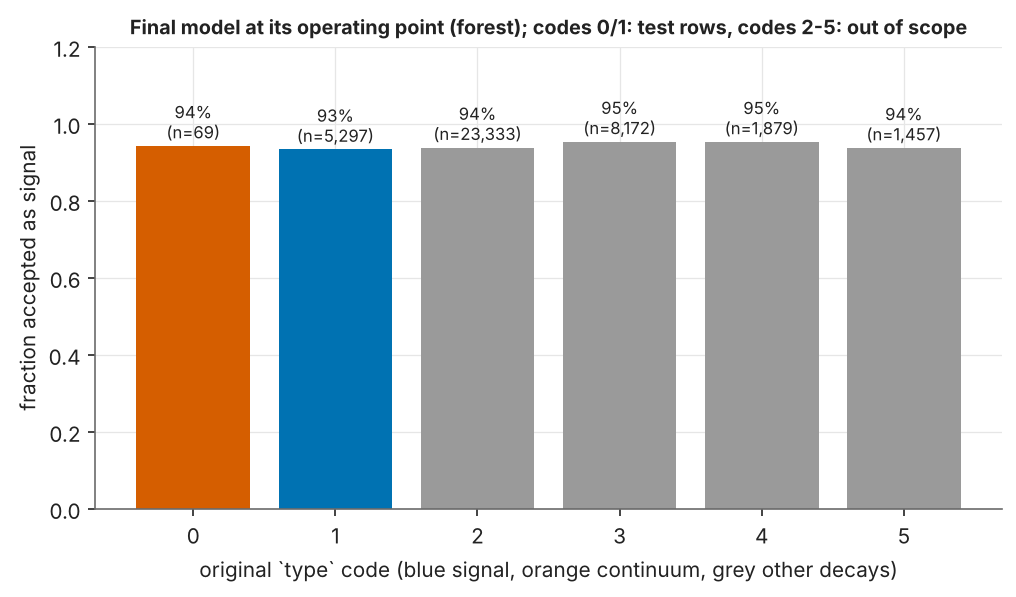

,type,role,rows_scored,scored_on,fraction_accepted_as_signal,mean_score
0,0,continuum,69,held-out test rows,0.942,0.987
1,1,signal,5297,held-out test rows,0.933,0.987
2,2,"other_decay (excluded, out of scope)",23333,all rows of the excluded code,0.938,0.987
3,3,"other_decay (excluded, out of scope)",8172,all rows of the excluded code,0.953,0.988
4,4,"other_decay (excluded, out of scope)",1879,all rows of the excluded code,0.953,0.988
5,5,"other_decay (excluded, out of scope)",1457,all rows of the excluded code,0.937,0.987


In [17]:
b = tlog['best_by_validation_auc']; bm = R.set_index('key').loc[b]
display(Markdown(f"**Selected model: `{b}`** - threshold {bm.threshold:.3f}. Test: signal efficiency {bm.op_signal_efficiency:.1%} [{bm.op_eff_lo:.1%}, {bm.op_eff_hi:.1%}] (n={n_sig}); continuum rejection {bm.op_continuum_rejection:.1%} [{bm.op_rej_lo:.1%}, {bm.op_rej_hi:.1%}] (n={n_con}); continuum acceptance {bm.op_continuum_acceptance:.1%}; ROC-AUC {bm.test_auc:.3f} [{bm.auc_ci_lo:.3f}, {bm.auc_ci_hi:.3f}]. Validation at the same threshold: efficiency {bm.val_op_signal_efficiency:.1%}, rejection {bm.val_op_continuum_rejection:.1%}."))
show('15_other_decays_diagnostic.png', 600); display(pd.read_csv(MET/'other_decays_diagnostic.csv').round(3))

The last table is **out of scope context**: the final model applied to the excluded other-decay codes 2-5 (never in training, validation or test). It is not a performance measure.

## 7. Reproducing predictions from the saved bundle

In [18]:
bundle = predict.load_bundle(MOD/'best_model.joblib'); print(bundle['model_name'], len(bundle['features']), 'features | frozen operating threshold', round(bundle['threshold'],4), '| mapping:', bundle['mapping']['status'])
ev = database.read_events(database.connect(cfg)); P = pd.read_csv(ART/'predictions/val_test_scores.csv', float_precision='round_trip'); te = P[P.split=='test']
out = predict.predict_df(ev.set_index('row_id').loc[te.row_id], bundle)
print('max |recomputed - saved score| =', float(np.abs(out.signal_score.to_numpy() - te[b].to_numpy()).max()))
for name, bad in (('missing column', raw.drop(columns=['R2']).head(3)), ('infinite value', raw.head(3).assign(thrust=np.inf)), ('non-numeric value', raw.head(3).astype({'thrust': object}).assign(thrust='abc'))):
    try: predict.predict_df(bad, bundle); print(name, '-> NOT rejected (unexpected)')
    except ValueError as e: print(name, '-> ValueError:', str(e)[:110])

forest 59 features | frozen operating threshold 0.97 | mapping: INSTRUCTOR-PROVIDED (relayed by the student on 30 Oct 2026); not verifiable from the data files themselves


max |recomputed - saved score| = 0.0
missing column -> ValueError: Input is missing 1 required feature column(s): ['R2']
infinite value -> ValueError: Non-numeric, missing or infinite values in column(s): ['thrust']
non-numeric value -> ValueError: Non-numeric, missing or infinite values in column(s): ['thrust']


## 8. Feature reduction

59 features -> 47 after |Spearman| < 0.95 filter -> 3 by permutation importance
criterion: smallest k with val AUC >= 0.995 x full-feature val AUC
reduced set: ['foxWolframR1', 'thrustBm', 'CleoConeCS__bo7__bc']


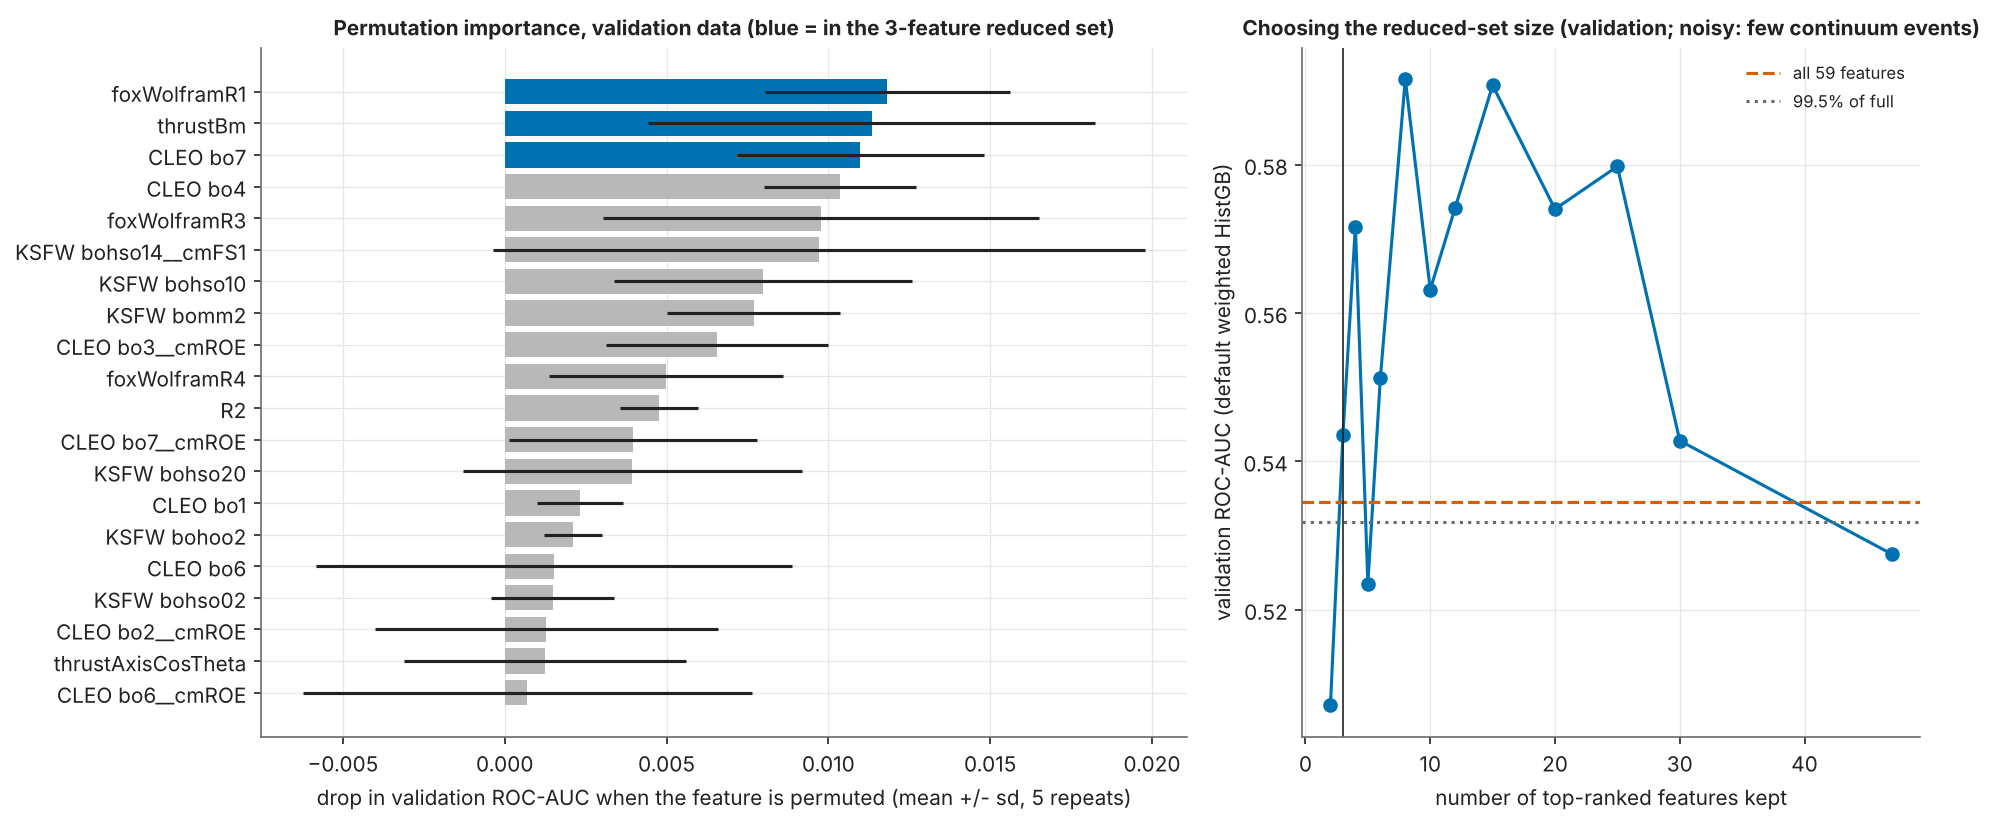

In [19]:
fr = tlog['feature_reduction']; print(fr['n_full'], 'features ->', fr['n_after_corr_filter'], 'after |Spearman| <', fr['corr_threshold'], 'filter ->', fr['k_selected'], 'by permutation importance'); print('criterion:', fr['criterion']); print('reduced set:', fr['reduced_features'])
show('16_feature_importance_reduction.png', 1100)

,Model,Feature set,Features,ROC-AUC,AUC diff vs full [95% paired CI],Signal eff.,Continuum rej. (n=69),Balanced acc.
0,Logistic regression,full,59,0.530,-,90.4%,11.6%,0.510
1,Logistic regression,corr_filtered,47,0.526,"-0.0030 [-0.0201, +0.0140]",90.0%,10.1%,0.501
2,Logistic regression,reduced,3,0.565,"+0.0360 [-0.0307, +0.1029]",89.6%,15.9%,0.528
3,Decision tree,full,59,0.522,-,93.4%,5.8%,0.496
4,Decision tree,corr_filtered,47,0.513,"-0.0084 [-0.0737, +0.0500]",96.0%,1.4%,0.487
5,Decision tree,reduced,3,0.568,"+0.0444 [-0.0308, +0.1240]",90.4%,17.4%,0.539
6,Random forest,full,59,0.505,-,93.3%,5.8%,0.495
7,Random forest,corr_filtered,47,0.497,"-0.0072 [-0.0872, +0.0683]",93.6%,4.3%,0.490
8,Random forest,reduced,3,0.548,"+0.0428 [-0.0275, +0.1121]",91.1%,7.2%,0.491
9,Gradient boosting (HistGB),full,59,0.545,-,90.7%,13.0%,0.519


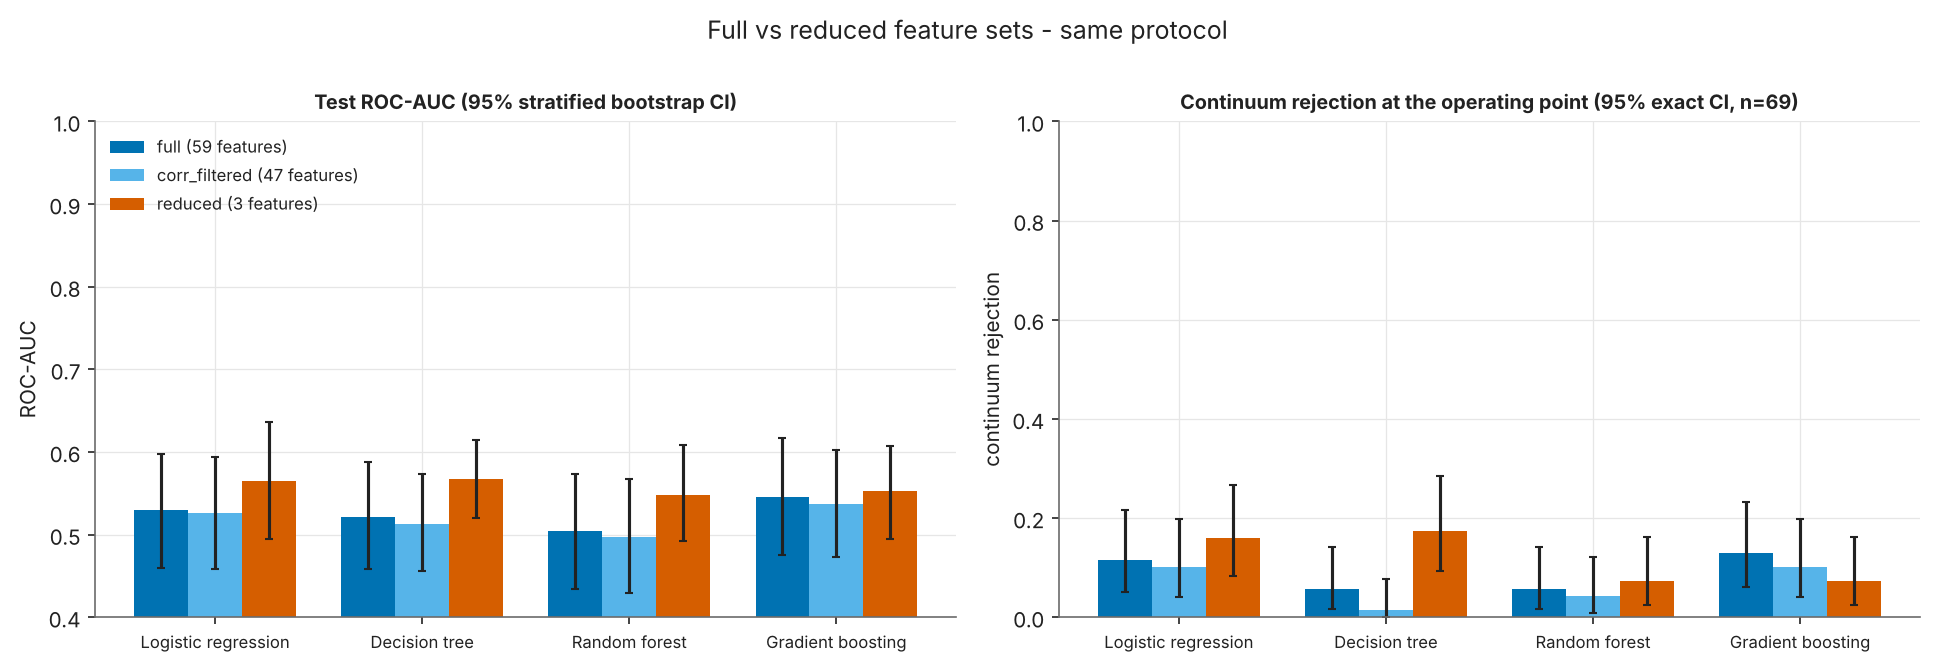

In [20]:
display(pd.read_csv(MET/'full_vs_reduced_table.csv')); show('17_full_vs_reduced.png', 1000)

**Method:** (1) drop one of each highly correlated pair (|Spearman| >= 0.95, keep the more separating feature, training rows); (2) rank by permutation importance of a class-weighted gradient-boosting model on *validation* data; (3) smallest k with val AUC >= 0.995 x full-feature val AUC. All four learned models were then re-tuned and re-evaluated with the identical protocol.
**Result:** correlation-filtered set (47 features), AUC change vs full: logistic regression -0.0030 (CI includes 0); decision tree -0.0084 (CI includes 0); random forest -0.0072 (CI includes 0); gradient boosting -0.0094 (CI includes 0). Reduced set (3 features): logistic regression +0.0360 (CI includes 0); decision tree +0.0444 (CI includes 0); random forest +0.0428 (CI includes 0); gradient boosting +0.0063 (CI includes 0). With so few continuum events the validation AUC used for these choices is noisy, so differences should not be over-read; importance is associational.

## 9. Pipeline checks (is the weak result a bug?) and robustness

In [21]:
sa = json.load(open(MET / 'sanity_audit.json'))
print('label alignment / positive class:', json.dumps(sa['label_alignment'], indent=1))
print('metrics recomputed with independent sklearn functions:', sa['metrics_recomputed_with_sklearn'])
print('negative control (shuffled training labels), validation AUC:', json.dumps(sa['negative_control']))
print('positive control (learnable task, same code path), validation AUC:', sa['positive_control']['validation_auc'], '|', sa['positive_control']['task'])
print('pooled train+validation 5-fold CV (test set NOT used):'); print(json.dumps(sa['pooled_train_val_5fold_cv'], indent=1))
print('verdict:', sa['verdict']); print(); print(sa['development_disclosure'])

label alignment / positive class: {
 "target_equals_(type==1)": true,
 "database_target_equals_pandas_target": true,
 "types_in_experiment": [
  0,
  1
 ],
 "n_signal": 35303,
 "n_continuum": 462,
 "all_saved_models_have_classes_[0,1]_so_predict_proba[:,1]_is_P(signal)": true,
 "positive_class_probe_auc_on_toy_task(should_be_~1)": 0.9999237107110162
}
metrics recomputed with independent sklearn functions: {'all_match': True, 'max_abs_difference': 2.220446049250313e-16}
negative control (shuffled training labels), validation AUC: {"logreg": {"validation_auc_with_shuffled_training_labels": [0.5417600978866589, 0.5369535437364508, 0.5515514237454947]}, "boosting": {"validation_auc_with_shuffled_training_labels": [0.4885209272632965, 0.5482557288965141, 0.5549082977563208]}}
positive control (learnable task, same code path), validation AUC: {'logreg': 0.9067583333333332, 'boosting': 0.923175} | type 1 vs type 2 (excluded code), balanced 4000/4000 sample, same features/splitting/models/metr

**Reading the checks.** Shuffled training labels give validation AUC 0.49-0.55 (no information); the same pipeline reaches 0.907 / 0.923 on a learnable task, so it can find separation when it exists; metrics recompute exactly with independent library functions; pooled train+validation CV (393 continuum events, no test data) gives out-of-fold AUC 0.549 [0.519, 0.578] (logistic) and 0.496 [0.467, 0.525] (boosting). No implementation problem was found, and **no physical separation is claimed**. Event-level leakage cannot be ruled out because no physical event identifier exists. The held-out test metrics of this corrected run were inspected while developing and debugging the reporting and the score-file precision fix. No model, hyper-parameter, feature set or threshold was changed in response to test results (they are fixed by validation data: see the isolation check). An earlier, different task (type 1 vs all other codes) used a different split of a different subset; its rows overlap with the current rows, so the current test rows are not strictly untouched by earlier work.

### Split variability

In [22]:
display(pd.read_csv(MET/'seed_repeats_summary.csv')); display(pd.read_csv(MET/'seed_repeats.csv').pivot_table(index='model', columns='seed', values='continuum_rej').round(3))

,model,auc_mean,auc_sd,eff_mean,rej_mean,rej_sd,rej_min,rej_max,n_splits
0,single_cut,0.5299,0.0338,0.9010,0.1183,0.0366,0.0725,0.1714,5
1,logreg,0.5340,0.0344,0.9030,0.1041,0.0375,0.0580,0.1594,5
2,tree,0.5258,0.0421,0.9237,0.0636,0.0164,0.0435,0.0870,5
3,forest,0.5131,0.0478,0.9253,0.0606,0.0232,0.0435,0.1000,5
4,boosting,0.5177,0.0394,0.8941,0.1275,0.0628,0.0286,0.2029,5


seed,1,2,3,4,42
model,,,,,
boosting,0.203,0.029,0.130,0.145,0.130
forest,0.058,0.100,0.043,0.043,0.058
logreg,0.087,0.100,0.159,0.058,0.116
majority,NaN,NaN,NaN,NaN,0.000
single_cut,0.116,0.171,0.101,0.072,0.130
tree,0.058,0.071,0.043,0.087,0.058


Re-splits with further seeds and *frozen* hyper-parameters (operating threshold re-selected on each split's validation set). The spread of continuum rejection across splits shows how much a single 69-event test set can move; the best model's AUC over 5 splits is 0.513 +/- 0.048 and its continuum rejection 6.1% (range 4.3% to 10.0%).

## 10. Conclusions and limitations

* **Task:** signal (type +1) vs continuum (type 0/-1) with instructor-provided code meanings (relayed by the student; unverifiable from the data). Codes 2-5 excluded by analysis decision. Only type 0 continuum exists (462 rows); no type -1 rows.
* The validation-selected model (Random forest) has test ROC-AUC 0.505 (close to chance); its 95% interval 0.434-0.573 includes 0.5 (chance). The highest test AUC among full-feature models is 0.567 (Single-feature cut, interval 0.504-0.630, which excludes 0.5 only barely; it was not the validation choice). Counting every feature-set variant (full, correlation-filtered, reduced), the highest test AUC is 0.568 (Decision tree, reduced features, interval 0.521-0.614); it too was not chosen on validation data. With 15 model / feature-set combinations scored on the same 69 continuum test events, one interval that excludes 0.5 is expected by chance alone and is not evidence of real separation. Among full-feature learned classifiers the AUC interval includes 0.5 for: Logistic regression, Decision tree, Random forest, Gradient boosting.
* On the instructor-provided mapping, at the validation-chosen operating point (signal efficiency floor 90%) the validation-selected model keeps 93.3% of true signal and rejects 5.8% of true continuum on the test set (only 69 continuum events; 95% exact interval 1.6%, 14.2%). For comparison, a score with no discrimination would reject about 6.7% at this efficiency.
* With the paired stratified bootstrap, the AUC difference between the selected model and the following models has an interval that includes zero, so no clear difference is established on this test set: Single-feature cut, Logistic regression, Decision tree, Gradient boosting.
* Feature reduction: correlation-filtered set - logistic regression -0.0030 (CI includes 0); decision tree -0.0084 (CI includes 0); random forest -0.0072 (CI includes 0); gradient boosting -0.0094 (CI includes 0); reduced set - logistic regression +0.0360 (CI includes 0); decision tree +0.0444 (CI includes 0); random forest +0.0428 (CI includes 0); gradient boosting +0.0063 (CI includes 0).
* **Flag for the instructor.** Under the instructor-provided mapping the type-0 events (the only continuum rows in the file; 0 type -1 rows exist) are, in these 59 features, nearly the same as the signal events: the best single feature (`thrustOm`) reaches an AUC of only 0.562 on the training rows, and no model separates the classes well. Physically, continuum (light-quark/charm) events are expected to be more jet-like (higher R2 and thrust, cosTBTO peaked at 1) than B-pair signal events; the type-0 events show the *signal-like* pattern instead (figure 3 and 4). This report does not change the mapping, but the data do not show the separation that a signal-versus-continuum task normally has, so it would be worth confirming with the instructor that code 0 really is continuum and that no type -1 data were meant to be included.
* Pipeline checks found no implementation problem (section 9); "signal-like" means only 'score above the threshold', not a known signal label. The held-out test metrics of this corrected run were inspected while developing and debugging the reporting and the score-file precision fix. No model, hyper-parameter, feature set or threshold was changed in response to test results (they are fixed by validation data: see the isolation check). An earlier, different task (type 1 vs all other codes) used a different split of a different subset; its rows overlap with the current rows, so the current test rows are not strictly untouched by earlier work.
* **Not established:** the mapping itself; absence of shared physical events across splits; any causal reading of importance; performance on real data. With 69 test continuum events all estimates are imprecise.